In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load database credentials from the .env file
load_dotenv()

# Check that all required variables are available
required_variables = [
    "DB_USER",
    "DB_PASSWORD",
    "DB_HOST",
    "DB_PORT",
    "DB_NAME"
]

missing_variables = [
    variable for variable in required_variables
    if not os.getenv(variable)
]

if missing_variables:
    raise ValueError(
        f"Missing environment variables: {missing_variables}"
    )

# Database schema
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

# Validate schema name
if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", schema):
    raise ValueError("Invalid database schema name.")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={
        "options": "-c default_transaction_read_only=on"
    }
)

# Test connection
with engine.connect() as connection:
    database_info = connection.execute(
        text("""
            SELECT
                current_database() AS database_name,
                current_user AS database_user,
                version() AS postgresql_version
        """)
    ).fetchone()

print("PostgreSQL connection successful!")
print("Database:", database_info.database_name)
print("User:", database_info.database_user)
print("Schema:", schema)
print("Version:", database_info.postgresql_version)

PostgreSQL connection successful!
Database: nf_da_onl_en_200726
User: atikesanli
Schema: s_atikesanli
Version: PostgreSQL 17.9 on x86_64-pc-linux-gnu, compiled by x86_64-pc-linux-gnu-gcc (GCC) 12.4.0, 64-bit


In [5]:
# Check the data type of product_categories
category_type_query = text("""
    SELECT
        column_name,
        data_type,
        udt_name
    FROM information_schema.columns
    WHERE table_schema = :schema
      AND table_name = 'int_order_customer_satisfaction'
      AND column_name = 'product_categories'
""")

with engine.connect() as connection:
    display(pd.read_sql_query(
        category_type_query,
        connection,
        params={"schema": schema}
    ))

# Inspect some example values
category_sample_query = text(f"""
    SELECT
        order_id,
        product_categories,
        average_review_score
    FROM {schema}.int_order_customer_satisfaction
    WHERE product_categories IS NOT NULL
      AND order_status = 'delivered'
    LIMIT 10
""")

with engine.connect() as connection:
    display(pd.read_sql_query(category_sample_query, connection))

,column_name,data_type,udt_name
0,product_categories,text,text


,order_id,product_categories,average_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,housewares,4.000
1,53cdb2fc8bc7dce0b6741e2150273451,perfumery,4.000
2,47770eb9100c2d0c44946d9cf07ec65d,auto,5.000
3,949d5b44dbf5de918fe9c16f97b45f8a,pet_shop,5.000
4,ad21c59c0840e6cb83a9ceb5573f8159,stationery,5.000
5,a4591c265e18cb1dcee52889e2d8acc3,auto,4.000
6,6514b8ad8028c9f2cc2374ded245783f,auto,5.000
7,76c6e866289321a7c93b82b54852dc33,furniture_decor,1.000
8,e69bfb5eb88e0ed6a785585b27e16dbf,office_furniture,5.000
9,e6ce16cb79ec1d90b1da9085a6118aeb,garden_tools,1.000


In [6]:
category_check_query = text(f"""
    SELECT
        product_categories,
        COUNT(*) AS number_of_orders
    FROM {schema}.int_order_customer_satisfaction
    WHERE order_status = 'delivered'
      AND chronology_status = 'Valid chronology'
      AND delivery_performance IN ('Late', 'On time or early')
      AND product_categories IS NOT NULL
      AND average_review_score IS NOT NULL
    GROUP BY product_categories
    ORDER BY number_of_orders DESC
""")

with engine.connect() as connection:
    category_counts = pd.read_sql_query(
        category_check_query,
        connection
    )

display(category_counts)
print("Number of distinct category values:", len(category_counts))

,product_categories,number_of_orders
0,bed_bath_table,8863
1,health_beauty,8480
2,sports_leisure,7357
3,computers_accessories,6393
4,furniture_decor,5999
...,...,...
323,"books_imported, unknown",1
324,"fixed_telephony, food",1
325,"fixed_telephony, telephony",1
326,"books_general_interest, housewares",1


Number of distinct category values: 328


In [8]:
rq4_query = text(f"""
    SELECT DISTINCT
        s.order_id,
        TRIM(category.category_name) AS product_category,
        s.average_review_score
    FROM {schema}.int_order_customer_satisfaction AS s
    CROSS JOIN LATERAL
        unnest(string_to_array(s.product_categories, ',')) 
        AS category(category_name)
    WHERE s.order_status = 'delivered'
      AND s.chronology_status = 'Valid chronology'
      AND s.delivery_performance IN ('Late', 'On time or early')
      AND s.product_categories IS NOT NULL
      AND s.average_review_score IS NOT NULL
""")

with engine.connect() as connection:
    rq4_df = pd.read_sql_query(rq4_query, connection)

print("Dataset shape:", rq4_df.shape)
print("Unique orders:", rq4_df["order_id"].nunique())
print("Unique categories:", rq4_df["product_category"].nunique())

display(rq4_df.head(10))

Dataset shape: (95944, 3)
Unique orders: 95178
Unique categories: 74


,order_id,product_category,average_review_score
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,5.000
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,4.000
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,5.000
3,00024acbcdf0a6daa1e931b038114c75,perfumery,4.000
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools,5.000
5,00048cc3ae777c65dbb7d2a0634bc1ea,housewares,4.000
6,00054e8431b9d7675808bcb819fb4a32,telephony,4.000
7,000576fe39319847cbb9d288c5617fa6,garden_tools,5.000
8,0005a1a1728c9d785b8e2b08b904576c,health_beauty,1.000
9,0005f50442cb953dcd1d21e1fb923495,books_technical,4.000


In [9]:
# Count orders and calculate average review score per category

category_summary = (
    rq4_df.groupby("product_category")
    .agg(
        number_of_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median"),
        standard_deviation=("average_review_score", "std")
    )
    .reset_index()
    .sort_values("number_of_orders", ascending=False)
)

# Identify categories with at least 50 orders
eligible_categories = category_summary[
    category_summary["number_of_orders"] >= 50
].copy()

# Identify categories excluded from the main analysis
excluded_categories = category_summary[
    category_summary["number_of_orders"] < 50
].copy()

print("Total categories:", len(category_summary))
print("Categories included:", len(eligible_categories))
print("Categories excluded:", len(excluded_categories))

display(eligible_categories.round(3))

Total categories: 74
Categories included: 59
Categories excluded: 15


,product_category,number_of_orders,average_review_score,median_review_score,standard_deviation
7,bed_bath_table,9057,4.004,5.000,1.366
43,health_beauty,8548,4.229,5.000,1.248
67,sports_leisure,7426,4.229,5.000,1.239
15,computers_accessories,6442,4.086,5.000,1.332
39,furniture_decor,6193,4.063,5.000,1.356
49,housewares,5677,4.198,5.000,1.244
73,watches_gifts,5434,4.121,5.000,1.313
70,telephony,4059,4.052,5.000,1.312
5,auto,3768,4.148,5.000,1.282
71,toys,3751,4.240,5.000,1.245


In [10]:
from scipy.stats import kruskal

# Keep only categories with at least 50 orders
categories_to_test = eligible_categories["product_category"].tolist()

# Create a review-score group for each category
review_groups = [
    rq4_df.loc[
        rq4_df["product_category"] == category,
        "average_review_score"
    ].values
    for category in categories_to_test
]

# Perform Kruskal-Wallis test
h_statistic, p_value = kruskal(*review_groups)

print("RQ4: PRODUCT CATEGORY AND CUSTOMER SATISFACTION")
print("-----------------------------------------------")
print("Number of categories:", len(review_groups))
print("Total category-order records:", sum(len(g) for g in review_groups))
print(f"Kruskal-Wallis H statistic: {h_statistic:.4f}")
print(f"P-value: {p_value:.6e}")

if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
else:
    print("Result: Fail to reject the null hypothesis.")

RQ4: PRODUCT CATEGORY AND CUSTOMER SATISFACTION
-----------------------------------------------
Number of categories: 59
Total category-order records: 95620
Kruskal-Wallis H statistic: 817.6982
P-value: 1.286578e-134
Result: Reject the null hypothesis.


In [11]:
from scipy.stats import rankdata, norm
from itertools import combinations

# Keep the 59 categories included in the main test
rq4_test_df = rq4_df[
    rq4_df["product_category"].isin(categories_to_test)
].copy()

# Calculate pooled ranks across all review scores
rq4_test_df["pooled_rank"] = rankdata(
    rq4_test_df["average_review_score"]
)

N = len(rq4_test_df)

# Correct for tied review scores
tie_counts = rq4_test_df["average_review_score"].value_counts()
tie_correction = 1 - (
    (tie_counts**3 - tie_counts).sum() / (N**3 - N)
)

# Calculate group sizes, mean ranks and mean scores
group_stats = (
    rq4_test_df.groupby("product_category")
    .agg(
        n=("average_review_score", "size"),
        mean_rank=("pooled_rank", "mean"),
        mean_score=("average_review_score", "mean")
    )
)

# Calculate all pairwise Dunn comparisons
results = []

for cat1, cat2 in combinations(categories_to_test, 2):

    g1 = group_stats.loc[cat1]
    g2 = group_stats.loc[cat2]

    variance = (
        N * (N + 1) / 12
        * tie_correction
        * (1 / g1["n"] + 1 / g2["n"])
    )

    z_score = (
        g1["mean_rank"] - g2["mean_rank"]
    ) / np.sqrt(variance)

    raw_p = 2 * norm.sf(abs(z_score))

    results.append({
        "category_1": cat1,
        "category_2": cat2,
        "mean_score_1": g1["mean_score"],
        "mean_score_2": g2["mean_score"],
        "mean_score_difference": (
            g1["mean_score"] - g2["mean_score"]
        ),
        "z_statistic": z_score,
        "p_value": raw_p
    })

dunn_results = pd.DataFrame(results)

# Apply Holm correction
m = len(dunn_results)

sorted_indices = np.argsort(dunn_results["p_value"].values)
sorted_p = dunn_results["p_value"].values[sorted_indices]

adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)
adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

adjusted_p = np.empty(m)
adjusted_p[sorted_indices] = adjusted_sorted

dunn_results["p_holm"] = adjusted_p

# Identify statistically significant pairs
significant_pairs = (
    dunn_results[dunn_results["p_holm"] < 0.05]
    .sort_values("p_holm")
)

print("Total pairwise comparisons:", m)
print("Significant comparisons after Holm correction:",
      len(significant_pairs))

display(significant_pairs.head(20).round(4))

Total pairwise comparisons: 1711
Significant comparisons after Holm correction: 202


,category_1,category_2,mean_score_1,mean_score_2,mean_score_difference,z_statistic,p_value,p_holm
75,health_beauty,office_furniture,4.229,3.644,0.585,15.893,0.000,0.000
636,perfumery,office_furniture,4.262,3.644,0.617,15.712,0.000,0.000
131,sports_leisure,office_furniture,4.229,3.644,0.585,15.457,0.000,0.000
495,toys,office_furniture,4.239,3.644,0.595,15.085,0.000,0.000
768,stationery,office_furniture,4.297,3.644,0.653,14.673,0.000,0.000
293,housewares,office_furniture,4.198,3.644,0.554,14.164,0.000,0.000
937,office_furniture,books_general_interest,3.644,4.534,-0.889,-13.945,0.000,0.000
543,cool_stuff,office_furniture,4.219,3.644,0.575,13.791,0.000,0.000
851,pet_shop,office_furniture,4.276,3.644,0.631,13.761,0.000,0.000
931,office_furniture,luggage_accessories,3.644,4.370,-0.726,-13.534,0.000,0.000


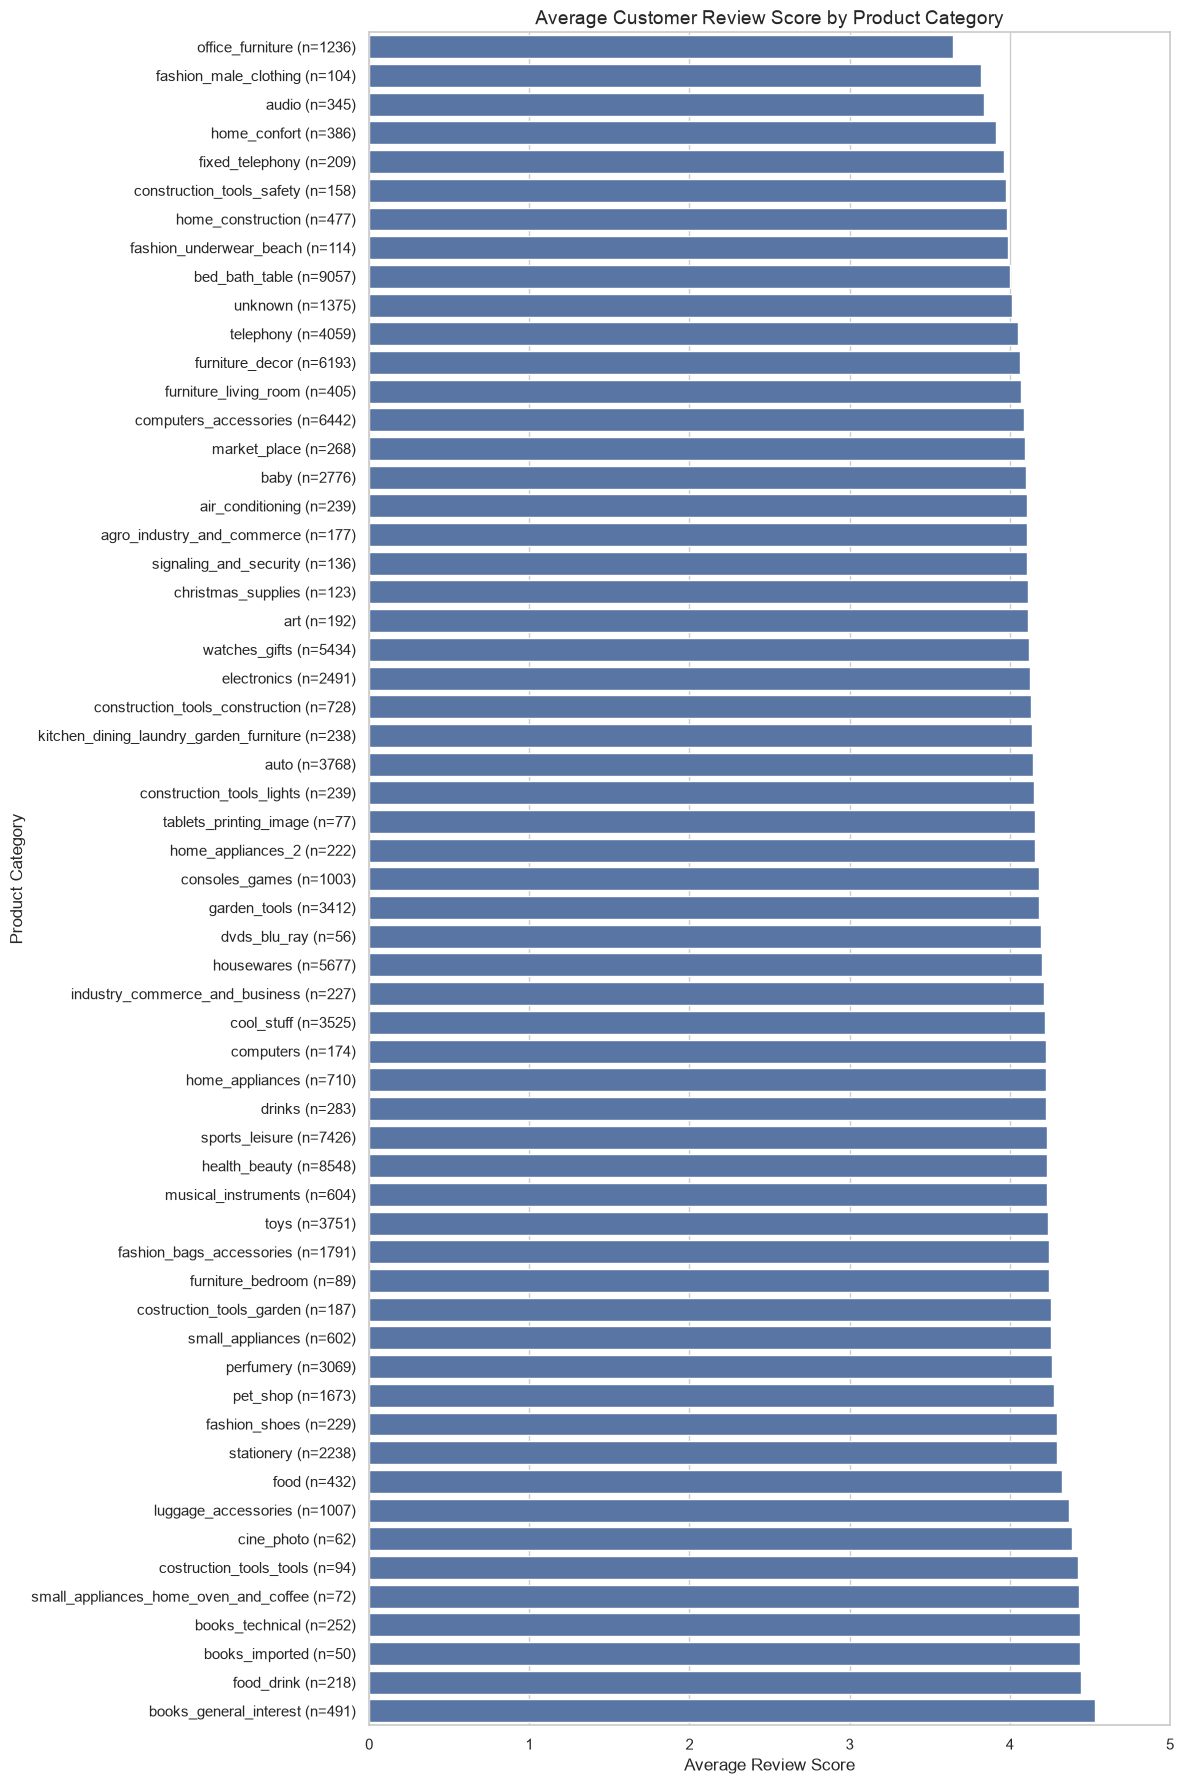

In [12]:
# Prepare category data for plotting
plot_df = eligible_categories.sort_values(
    "average_review_score",
    ascending=True
).copy()

# Include sample size in category labels
plot_df["category_label"] = (
    plot_df["product_category"]
    + " (n="
    + plot_df["number_of_orders"].astype(str)
    + ")"
)

plt.figure(figsize=(12, 18))

ax = sns.barplot(
    data=plot_df,
    x="average_review_score",
    y="category_label"
)

ax.set_title(
    "Average Customer Review Score by Product Category",
    fontsize=14
)
ax.set_xlabel("Average Review Score")
ax.set_ylabel("Product Category")
ax.set_xlim(0, 5)

plt.tight_layout()

os.makedirs("../figures", exist_ok=True)

plt.savefig(
    "../figures/rq4_category_review_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Show the 10 largest absolute mean-score differences
largest_differences = (
    dunn_results
    .assign(
        absolute_difference=lambda x:
            x["mean_score_difference"].abs()
    )
    .sort_values("absolute_difference", ascending=False)
    .head(10)
)

display(
    largest_differences[
        [
            "category_1",
            "category_2",
            "mean_score_difference",
            "p_holm"
        ]
    ].round(6)
)

,category_1,category_2,mean_score_difference,p_holm
937,office_furniture,books_general_interest,-0.889,0.000
952,office_furniture,food_drink,-0.801,0.000
969,office_furniture,books_imported,-0.796,0.001
945,office_furniture,books_technical,-0.792,0.000
966,office_furniture,small_appliances_home_oven_and_coffee,-0.786,0.000
963,office_furniture,costruction_tools_tools,-0.781,0.000
967,office_furniture,cine_photo,-0.743,0.001
931,office_furniture,luggage_accessories,-0.726,0.000
1207,books_general_interest,fashion_male_clothing,0.716,0.008
1187,books_general_interest,audio,0.693,0.000


### Product Categories and Customer Satisfaction

The relationship between product category and customer satisfaction was examined using the Kruskal–Wallis test. The analysis included 59 product categories, each with at least 50 orders, representing 95,620 order-category observations.

The results indicated statistically significant differences in customer review-score distributions across product categories (H = 817.70, p < .001). Therefore, the null hypothesis was rejected.

To identify which categories differed, Dunn's post-hoc pairwise comparisons with Holm correction were conducted. Of the 1,711 pairwise comparisons, 202 remained statistically significant after adjustment for multiple testing. Notably, the office furniture category recorded a comparatively low average review score (M = 3.644), while categories such as books general interest (M = 4.534) and luggage accessories (M = 4.370) recorded higher averages.

These findings suggest that customer satisfaction varies across product categories. However, the results should be interpreted cautiously because orders containing multiple product categories contribute the same order-level review score to more than one category. Consequently, the category observations are not entirely independent. The findings indicate an association between product category and customer satisfaction, rather than a causal relationship.

Examination of the largest pairwise differences revealed that office furniture had notably lower average review scores than several other product categories. The largest difference was observed between office furniture (M = 3.644) and books general interest (M = 4.534), representing a difference of 0.889 points on the five-point review scale. Significant differences were also identified between office furniture and categories such as food and drink, imported books, technical books, and luggage accessories. These findings suggest that customer satisfaction varies meaningfully across certain product categories, although the results do not establish that product category itself causes differences in satisfaction.

A sensitivity analysis was conducted to address the potential lack of independence arising from orders containing products from multiple categories. The analysis was repeated using only orders associated with exactly one product category. This resulted in 94,134 observations across 58 categories with at least 50 orders. The Kruskal–Wallis test remained statistically significant (H = 778.40, p < .001), consistent with the original analysis (H = 817.70, p < .001). The consistency of these findings suggests that the observed differences in customer satisfaction across product categories are robust and are not primarily driven by orders appearing in multiple category groups.

In [15]:
orders_per_category = (
    rq4_test_df.groupby("order_id")["product_category"]
    .nunique()
)

print(
    "Orders appearing in multiple categories:",
    (orders_per_category > 1).sum()
)

print(
    "Percentage of orders appearing in multiple categories:",
    round((orders_per_category > 1).mean() * 100, 2),
    "%"
)

print(
    "Maximum categories per order:",
    orders_per_category.max()
)

Orders appearing in multiple categories: 735
Percentage of orders appearing in multiple categories: 0.77 %
Maximum categories per order: 3


In [16]:
# Identify orders that appear in exactly one category
single_category_orders = orders_per_category[
    orders_per_category == 1
].index

# Keep only those orders
rq4_single_df = rq4_test_df[
    rq4_test_df["order_id"].isin(single_category_orders)
].copy()

# Summarise the remaining categories
single_category_summary = (
    rq4_single_df.groupby("product_category")
    .agg(
        number_of_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean")
    )
    .reset_index()
    .sort_values("number_of_orders", ascending=False)
)

print("Remaining observations:", len(rq4_single_df))
print("Remaining unique orders:", rq4_single_df["order_id"].nunique())
print("Remaining categories:", rq4_single_df["product_category"].nunique())

display(single_category_summary)

Remaining observations: 94134
Remaining unique orders: 94134
Remaining categories: 59


,product_category,number_of_orders,average_review_score
6,bed_bath_table,8864,4.023
35,health_beauty,8480,4.236
52,sports_leisure,7357,4.241
13,computers_accessories,6393,4.093
32,furniture_decor,6000,4.096
40,housewares,5566,4.221
58,watches_gifts,5396,4.129
55,telephony,4033,4.060
4,auto,3734,4.161
56,toys,3702,4.251


In [17]:
from scipy.stats import kruskal

# Keep orders that appear in exactly one product category
single_category_orders = orders_per_category[
    orders_per_category == 1
].index

single_category_df = rq4_test_df[
    rq4_test_df["order_id"].isin(single_category_orders)
].copy()

# Recalculate category sample sizes and average scores
single_category_summary = (
    single_category_df.groupby("product_category")
    .agg(
        number_of_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean")
    )
    .reset_index()
    .sort_values("number_of_orders", ascending=False)
)

# Retain categories with at least 50 orders
single_eligible_categories = single_category_summary[
    single_category_summary["number_of_orders"] >= 50
].copy()

categories_to_test_single = (
    single_eligible_categories["product_category"].tolist()
)

# Prepare review-score groups
single_review_groups = [
    single_category_df.loc[
        single_category_df["product_category"] == category,
        "average_review_score"
    ]
    for category in categories_to_test_single
]

# Run Kruskal-Wallis test
single_kw_stat, single_kw_p = kruskal(*single_review_groups)

print("Sensitivity analysis: single-category orders only")
print("Observations:", len(single_category_df))
print("Unique orders:", single_category_df["order_id"].nunique())
print("Categories before threshold:", single_category_df["product_category"].nunique())
print("Categories included in test:", len(categories_to_test_single))
print("Kruskal-Wallis H:", single_kw_stat)
print("p-value:", single_kw_p)

display(single_eligible_categories)

Sensitivity analysis: single-category orders only
Observations: 94134
Unique orders: 94134
Categories before threshold: 59
Categories included in test: 58
Kruskal-Wallis H: 778.401358128487
p-value: 2.9865986545497066e-127


,product_category,number_of_orders,average_review_score
6,bed_bath_table,8864,4.023
35,health_beauty,8480,4.236
52,sports_leisure,7357,4.241
13,computers_accessories,6393,4.093
32,furniture_decor,6000,4.096
40,housewares,5566,4.221
58,watches_gifts,5396,4.129
55,telephony,4033,4.060
4,auto,3734,4.161
56,toys,3702,4.251


In [18]:
from scipy.stats import rankdata, norm
from itertools import combinations

# Rank all review scores together
single_category_df["pooled_rank"] = rankdata(
    single_category_df["average_review_score"]
)

N = len(single_category_df)

# Tie correction
tie_counts = single_category_df[
    "average_review_score"
].value_counts()

tie_correction = 1 - (
    (tie_counts**3 - tie_counts).sum()
    / (N**3 - N)
)

# Calculate category statistics
single_group_stats = (
    single_category_df.groupby("product_category")
    .agg(
        n=("average_review_score", "size"),
        mean_rank=("pooled_rank", "mean"),
        mean_score=("average_review_score", "mean")
    )
)

# Dunn pairwise comparisons
single_dunn_results = []

for cat1, cat2 in combinations(categories_to_test_single, 2):

    g1 = single_group_stats.loc[cat1]
    g2 = single_group_stats.loc[cat2]

    variance = (
        N * (N + 1) / 12
        * tie_correction
        * (1 / g1["n"] + 1 / g2["n"])
    )

    z_score = (
        g1["mean_rank"] - g2["mean_rank"]
    ) / np.sqrt(variance)

    raw_p = 2 * norm.sf(abs(z_score))

    single_dunn_results.append({
        "category_1": cat1,
        "category_2": cat2,
        "mean_score_difference": (
            g1["mean_score"] - g2["mean_score"]
        ),
        "p_value": raw_p
    })

single_dunn_results = pd.DataFrame(single_dunn_results)

# Holm correction
m = len(single_dunn_results)

sorted_indices = np.argsort(
    single_dunn_results["p_value"].values
)

sorted_p = single_dunn_results[
    "p_value"
].values[sorted_indices]

adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)

adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

adjusted_p = np.empty(m)
adjusted_p[sorted_indices] = adjusted_sorted

single_dunn_results["p_holm"] = adjusted_p

# Significant comparisons
single_significant_pairs = single_dunn_results[
    single_dunn_results["p_holm"] < 0.05
].copy()

print("Total pairwise comparisons:", m)
print(
    "Significant comparisons after Holm correction:",
    len(single_significant_pairs)
)

# Show the largest significant differences
largest_single_differences = (
    single_significant_pairs
    .assign(
        absolute_difference=lambda x:
        x["mean_score_difference"].abs()
    )
    .sort_values("absolute_difference", ascending=False)
    .head(10)
)

display(
    largest_single_differences[
        [
            "category_1",
            "category_2",
            "mean_score_difference",
            "p_holm"
        ]
    ].round(6)
)

Total pairwise comparisons: 1653
Significant comparisons after Holm correction: 181


,category_1,category_2,mean_score_difference,p_holm
918,office_furniture,books_general_interest,-0.879,0.000
933,office_furniture,food_drink,-0.784,0.000
948,office_furniture,cine_photo,-0.783,0.000
926,office_furniture,books_technical,-0.782,0.000
947,office_furniture,small_appliances_home_oven_and_coffee,-0.771,0.001
944,office_furniture,costruction_tools_tools,-0.766,0.000
1181,books_general_interest,fashion_male_clothing,0.722,0.006
913,office_furniture,luggage_accessories,-0.722,0.000
1160,books_general_interest,audio,0.687,0.000
920,office_furniture,food,-0.675,0.000


### RQ4: Relationship Between Product Categories and Customer Satisfaction

The relationship between product category and customer satisfaction was examined using the Kruskal–Wallis test. The initial analysis included 59 product categories, each with at least 50 orders, representing 95,620 order-category observations.

The results indicated statistically significant differences in customer review-score distributions across product categories (H = 817.70, p < .001). Therefore, the null hypothesis was rejected.

To identify which categories differed, Dunn's post-hoc pairwise comparisons with Holm correction were conducted. Of the 1,711 pairwise comparisons, 202 remained statistically significant after adjustment for multiple testing. The largest difference was observed between office furniture (M = 3.644) and books general interest (M = 4.534), representing a difference of 0.889 points on the five-point review scale. Office furniture also recorded notably lower average review scores than categories such as food and drink, technical books, and luggage accessories.

A sensitivity analysis was conducted to address the potential lack of independence arising from orders containing products from multiple categories. The analysis was repeated using only orders associated with exactly one product category. This resulted in 94,134 observations across 58 categories with at least 50 orders. The Kruskal–Wallis test remained statistically significant (H = 778.40, p < .001). Furthermore, 181 of the 1,653 Dunn pairwise comparisons remained statistically significant after Holm correction. The largest difference continued to be between office furniture and books general interest (0.879 points).

The consistency of the findings across the original and sensitivity analyses suggests that customer satisfaction varies across product categories and that these differences are not primarily driven by orders appearing in multiple category groups. However, these findings indicate an association rather than a causal relationship.